# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
# Add code here 🔧
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv"
df = pd.read_csv(url)

display(df.head())
display(df.describe())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. There are some missing values in columns such as agent and company or unusual values such as negative ADR.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
# Add code here 🔧
from sklearn.preprocessing import StandardScaler

features = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adr', 'total_of_special_requests']

df = df.drop_duplicates().copy()
df[features] = df[features].apply(pd.to_numeric, errors='coerce')
df = df.dropna(subset=features)
df = df[(df['adr'] >= 0) & (df['lead_time'] >= 0)]

for col in features:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    if IQR > 0:
        df = df[df[col].between(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)]

X_scaled = StandardScaler().fit_transform(df[features])

print("Cleaned data:", df.shape)
print("Scaled data:", X_scaled.shape)

Cleaned data: (6967, 32)
Scaled data: (6967, 5)


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead time, stays in weekend nights, stays in week nights, adr, and total of special requests. They can be used to explain customer behavior, spending and preferences.

2. People who book early or at last minute, guests who stay longers and customers who spends more money


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

cluster
0    2718
1    1663
2    1307
3    1279
Name: count, dtype: int64


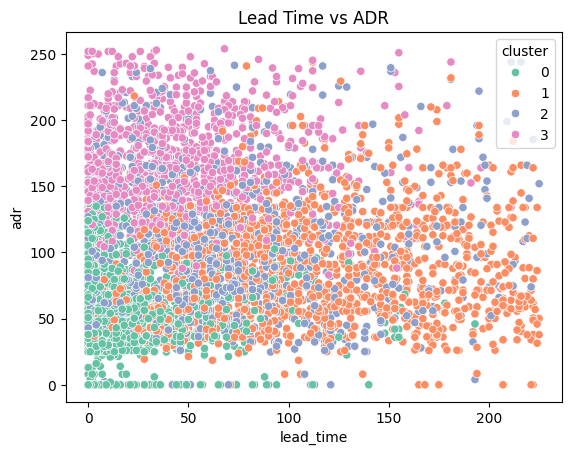

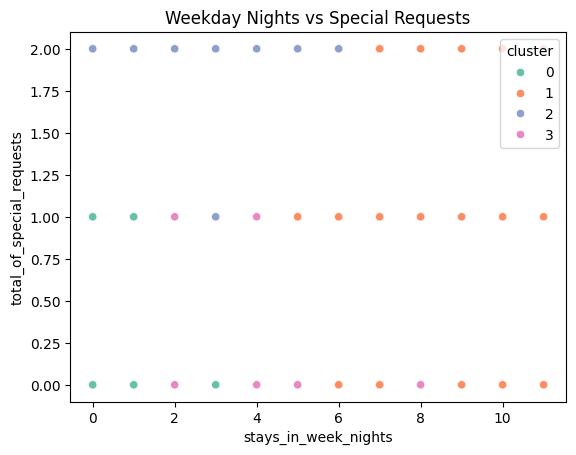

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
cluster,,,,,
0,14.48,0.43,1.38,52.71,0.29
1,104.96,2.32,5.68,86.59,0.46
2,65.96,1.01,2.89,102.26,1.71
3,44.86,1.13,3.09,161.38,0.36


In [3]:
# Add code here 🔧
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print(df['cluster'].value_counts())

sns.scatterplot(data=df, x='lead_time', y='adr', hue='cluster', palette='Set2')
plt.title('Lead Time vs ADR')
plt.show()

sns.scatterplot(data=df, x='stays_in_week_nights', y='total_of_special_requests',
                hue='cluster', palette='Set2')
plt.title('Weekday Nights vs Special Requests')
plt.show()

display(df.groupby('cluster')[features].mean().round(2))

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I choose k = 4 as I wanted to divide customers into four different groups based on their booking behavior.

2.
Cluster 0 = Budget travlers with short stays. Low ADR and lead time
Cluster 1 = Guests who book early and stay longer. High lead time and more nights
Cluster 2 = Guests with more special requests
Cluster 3 =  Higher spending guests. High ADR

## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

gmm_cluster
3    2800
1    1761
0    1393
2    1013
Name: count, dtype: int64
[[0.583 0.007 0.    0.411]
 [0.    0.018 0.    0.982]
 [0.    0.033 0.    0.967]
 [0.578 0.007 0.    0.415]
 [0.011 0.031 0.    0.958]]


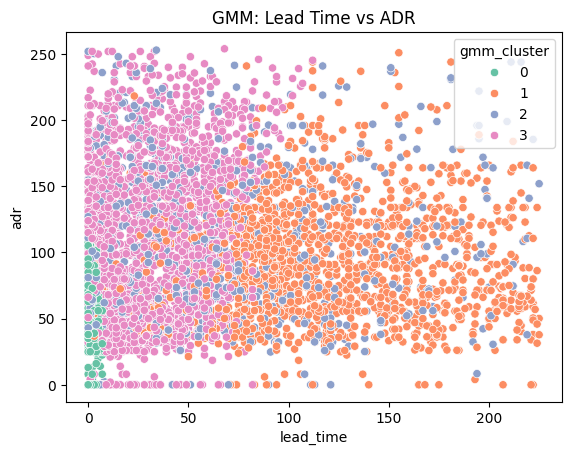

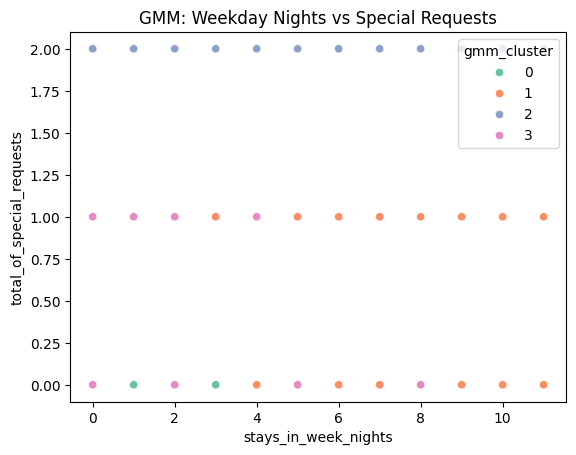

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
gmm_cluster,,,,,
0,1.68,0.23,1.03,47.07,0.28
1,117.28,1.90,4.95,90.15,0.44
2,61.93,1.19,3.25,106.23,2.00
3,30.67,1.04,2.68,105.50,0.38


In [4]:
# Add your code here
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=4, random_state=42)
gmm.fit(X_scaled)

df['gmm_cluster'] = gmm.predict(X_scaled)
probabilities = gmm.predict_proba(X_scaled)

print(df['gmm_cluster'].value_counts())
print(probabilities[:5].round(3))

sns.scatterplot(data=df, x='lead_time', y='adr',
                hue='gmm_cluster', palette='Set2')
plt.title('GMM: Lead Time vs ADR')
plt.show()

sns.scatterplot(data=df, x='stays_in_week_nights',
                y='total_of_special_requests',
                hue='gmm_cluster', palette='Set2')
plt.title('GMM: Weekday Nights vs Special Requests')
plt.show()

display(df.groupby('gmm_cluster')[features].mean().round(2))

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. Both models produced four groups with similar trends, though the sizes of the clusters varied. GMM also gave us probabilities, whereas KMeans assigned each customer to one cluster.

2. GMM can allow hotels to identify those customers who belong to more than one group. This can help companies with things such as choosing which do's and don'ts to recommend to customers.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [5]:
# Add code here 🔧
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

for name, labels in [('KMeans', kmeans.labels_), ('GMM', gmm.predict(X_scaled))]:
    wcss = sum(((X_scaled[labels == i] - X_scaled[labels == i].mean(axis=0))**2).sum() for i in np.unique(labels))
    print(name)
    print("WCSS:", round(wcss, 2))
    print("Silhouette Score:", round(silhouette_score(X_scaled, labels, sample_size=3000, random_state=42), 3))
    print("Davies-Bouldin Index:", round(davies_bouldin_score(X_scaled, labels), 3))

KMeans
WCSS: 17551.35
Silhouette Score: 0.267
Davies-Bouldin Index: 1.374
GMM
WCSS: 20847.92
Silhouette Score: 0.133
Davies-Bouldin Index: 1.645


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. Kmeans, it has lower WCSS, a higher silouette score and lower daives bouldin index

5.3. I recommend Kmeans as it has better three metrics and it is simpler to understand and easier to use


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [6]:
# Add code here 🔧
summary = df.groupby('cluster')[features].mean().round(2)
display(summary.sort_values('lead_time'))

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
cluster,,,,,
0,14.48,0.43,1.38,52.71,0.29
3,44.86,1.13,3.09,161.38,0.36
2,65.96,1.01,2.89,102.26,1.71
1,104.96,2.32,5.68,86.59,0.46


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Cluster 0 is travelrs with short stays, cluster 3 is high spending customers, cluster 2 is more special guests and cluster 1 is guests who book early and stay longer.

2. The hotel may provide budget packages to Cluster 0, long-stay discounts to Cluster 1, customized services to the Cluster 2 and premium packages, upgrades to a room to the Cluster 3.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Choosing the right number of clusters and understanding what each group represents.

2. When there are no predefined labels and to discover trends or patterns in the data.

3. Clustering help businesses to group similar customers to create more effective marketing strategies.

4. My learning outcome is to interpret financial data and invest better. With this task I learnt to prepare data, clustering and assess models, which can be used to find trends in the financial markets.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"